In [1]:
import sys
sys.path.insert(0, "../src")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Audio, display
from sklearn.ensemble import HistGradientBoostingClassifier

from features import (SR, FRAME, HOP, MFCC_FEATURES, TIME_FEATURES, TIME_CONTEXT_FEATURES, extract_features)
from dataset import load_wav, list_clips, speech_labels, mix, build_frame_table, SNR_LEVELS, DATA_DIR
from evaluate import scores, fit_model, test_single_feature

results_dir = Path("../results")
results_dir.mkdir(exist_ok=True)

# Feature groups
FREQ_FEATURES = ["centroid", "flatness", "flux", "band_ratio"]                 # computed from the spectrum
FREQ_CONTEXT_FEATURES = [f"{n}_{s}" for n in FREQ_FEATURES for s in ("mean", "std")]
ALL_FEATURES = TIME_FEATURES + TIME_CONTEXT_FEATURES + FREQ_FEATURES + FREQ_CONTEXT_FEATURES + MFCC_FEATURES


def fit_trees(table, features, target="speech"):
    """Gradient boosting: many small decision trees, so it can learn rules like 'loud AND not pitched'."""
    model = HistGradientBoostingClassifier(max_iter=200, class_weight="balanced", random_state=0)
    model.fit(table[features].values, table[target].values)
    return model

In [2]:
train = build_frame_table("train")
test = build_frame_table("test")
print("Train frames:", len(train), "| Test frames:", len(test))
display(test.groupby(["condition", "klass"]).size().unstack(fill_value=0))

Train frames: 299700 | Test frames: 199800


klass,noise,silence,speech
condition,,,
clean speech,0,6427,33533
noise only,39960,0,0
speech + noise 0 dB,6427,0,33533
speech + noise 10 dB,6427,0,33533
speech + noise 20 dB,6427,0,33533


In [3]:
groups = {
    "silence": test["klass"] == "silence",
    "noise": test["klass"] == "noise",
    "speech (clean)": (test["klass"] == "speech") & (test["condition"] == "clean speech"),
    "speech (10 dB noise)": (test["klass"] == "speech") & (test["condition"] == "speech + noise 10 dB"),
}
time_values = pd.DataFrame({name: test.loc[mask, TIME_FEATURES].median() for name, mask in groups.items()})
display(time_values.round(3))
time_values.round(4).to_csv(results_dir / "table_A1_time_feature_values.csv")

,silence,noise,speech (clean),speech (10 dB noise)
energy_db,-51.910,-32.978,-22.464,-21.806
magnitude_db,-53.844,-34.871,-24.507,-23.825
teager_db,-61.742,-45.324,-33.035,-31.854
zcr,0.115,0.043,0.060,0.068
energy_entropy,0.908,0.920,0.912,0.922
harmonicity,0.237,0.230,0.512,0.419
amdf_periodicity,0.231,0.215,0.583,0.427
pitch_hz,133.333,166.667,134.454,135.593


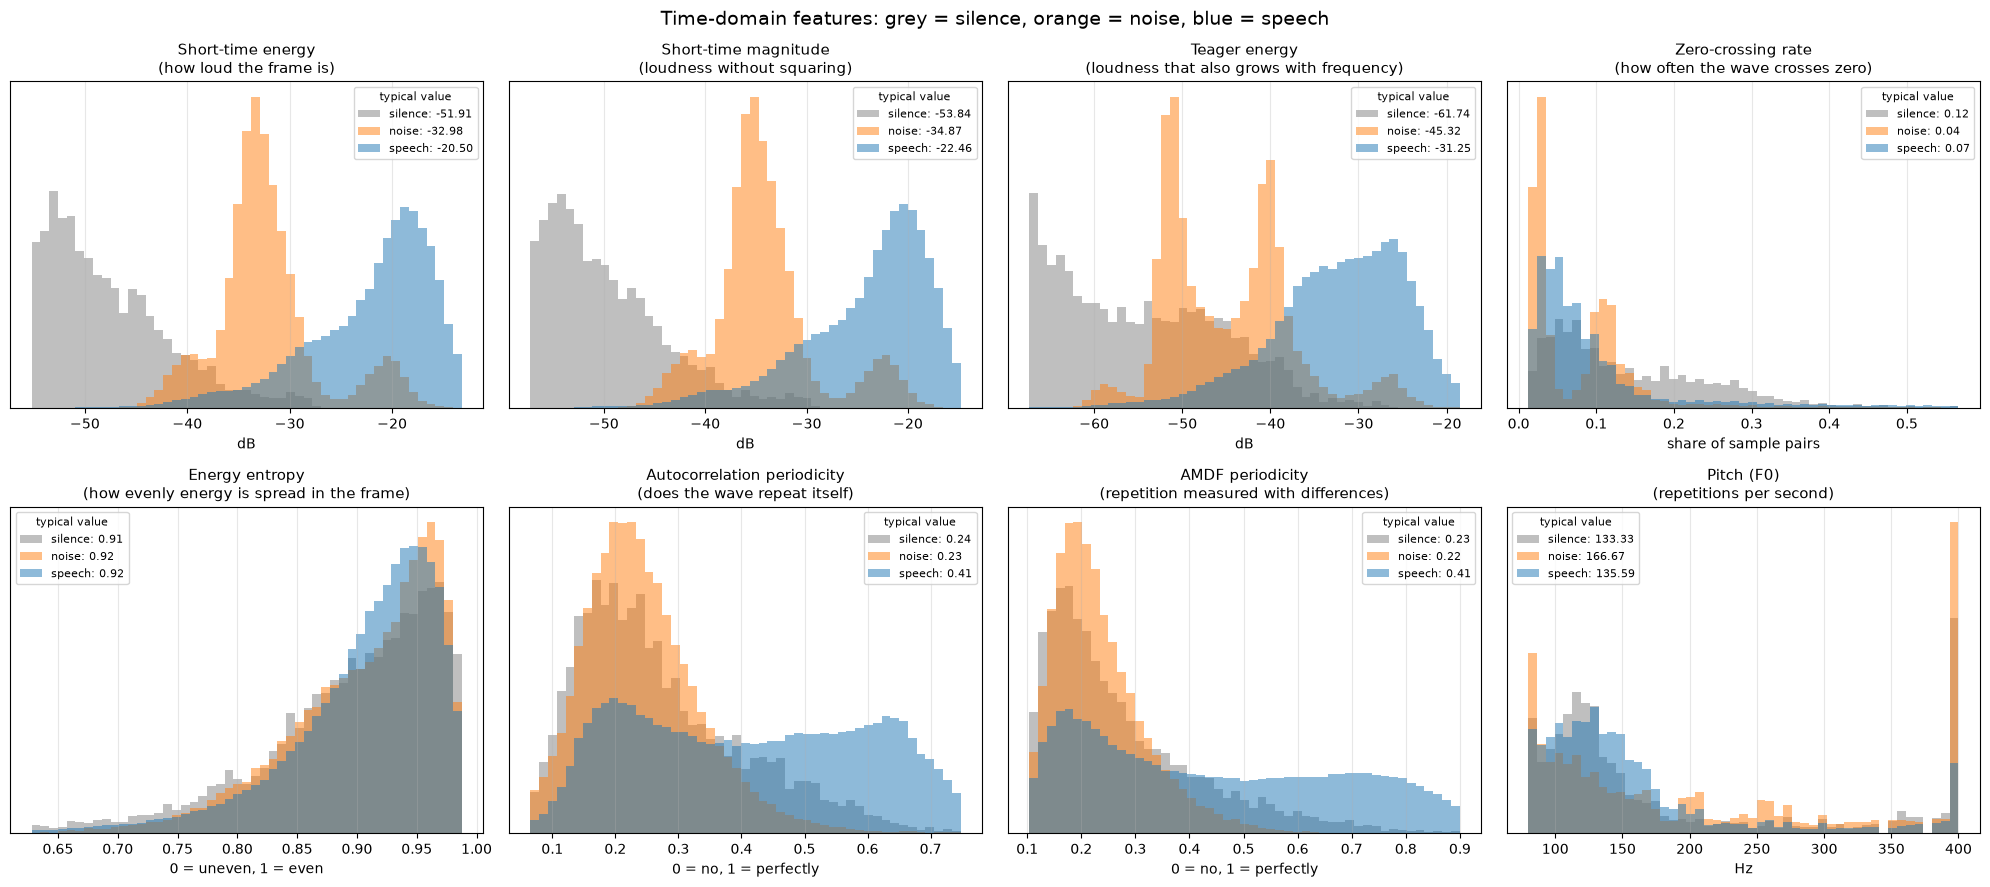

In [4]:
descriptions = {
    "energy_db":        ("Short-time energy", "how loud the frame is", "dB"),
    "magnitude_db":     ("Short-time magnitude", "loudness without squaring", "dB"),
    "teager_db":        ("Teager energy", "loudness that also grows with frequency", "dB"),
    "zcr":              ("Zero-crossing rate", "how often the wave crosses zero", "share of sample pairs"),
    "energy_entropy":   ("Energy entropy", "how evenly energy is spread in the frame", "0 = uneven, 1 = even"),
    "harmonicity":      ("Autocorrelation periodicity", "does the wave repeat itself", "0 = no, 1 = perfectly"),
    "amdf_periodicity": ("AMDF periodicity", "repetition measured with differences", "0 = no, 1 = perfectly"),
    "pitch_hz":         ("Pitch (F0)", "repetitions per second", "Hz"),
}
colours = {"silence": "grey", "noise": "tab:orange", "speech": "tab:blue"}

fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for ax, feature in zip(axes.ravel(), TIME_FEATURES):
    name, meaning, unit = descriptions[feature]
    low, high = np.percentile(test[feature], [1, 99])
    bins = np.linspace(low, high, 50)
    for klass, colour in colours.items():
        values = test.loc[test["klass"] == klass, feature]
        ax.hist(values, bins=bins, density=True, alpha=0.5, color=colour, label=f"{klass}: {values.median():.2f}")
    ax.set_title(f"{name}\n({meaning})", fontsize=11)
    ax.set_xlabel(unit, fontsize=10)
    ax.set_yticks([])                                   # the height only shows "more / less often"
    ax.legend(fontsize=8, title="typical value", title_fontsize=8)
    ax.grid(alpha=0.3)
plt.suptitle("Time-domain features: grey = silence, orange = noise, blue = speech", fontsize=14)
plt.tight_layout(); plt.show()

,task,audio detection,speech detection
feature,domain,,
energy_db,time,0.945,0.855
magnitude_db,time,0.946,0.852
teager_db,time,0.837,0.836
amdf_periodicity,time,0.590,0.727
harmonicity,time,0.600,0.725
centroid,frequency,0.792,0.659
flux,frequency,0.536,0.650
flatness,frequency,0.792,0.641
pitch_hz,time,0.532,0.623


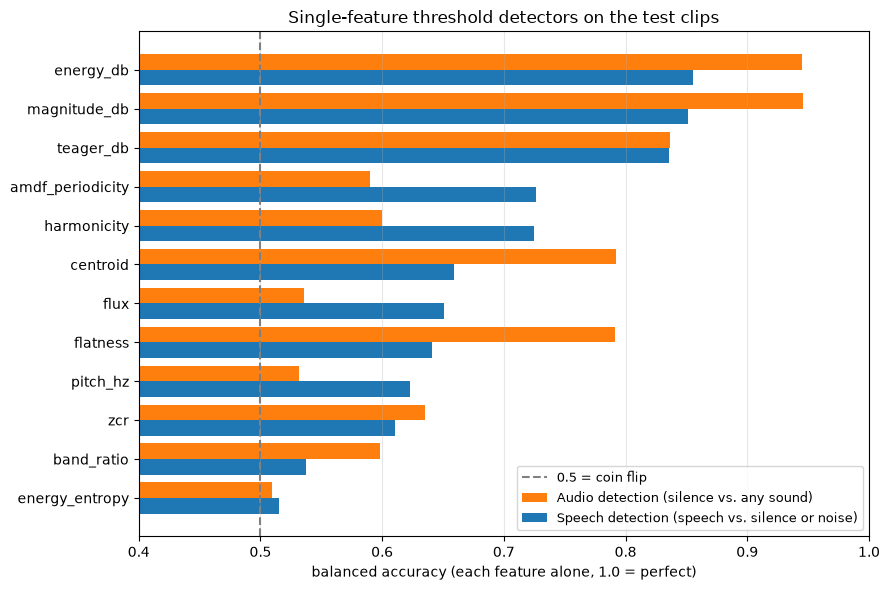

In [8]:
rows = []
targets = {"audio": "audio detection", "speech": "speech detection"}
for target, label in targets.items():
    for domain, feature_list in [("time", TIME_FEATURES), ("frequency", FREQ_FEATURES)]:
        for feature in feature_list:
            result = test_single_feature(train, test, feature, target)
            rows.append({"task": label, "feature": feature, "domain": domain,
                         "balanced_acc": result["balanced_acc"], "miss_rate": result["miss_rate"],
                         "false_alarm": result["false_alarm"], "rule": result["rule"]})
table_b = pd.DataFrame(rows)
table_b.round(4).to_csv(results_dir / "table_B_single_features.csv", index=False)   # full table is saved to a file

# Compact table: one row per feature, one column per task
compact = table_b.pivot_table(index=["feature", "domain"], columns="task", values="balanced_acc")
compact = compact[["audio detection", "speech detection"]].sort_values("speech detection", ascending=False)
display(compact.round(3))

# Bar chart: each feature alone, both tasks side by side
order = compact.index.get_level_values("feature")[::-1]          # best feature on top
y = np.arange(len(order))
audio_scores = compact["audio detection"].values[::-1]
speech_scores = compact["speech detection"].values[::-1]

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(y + 0.2, audio_scores, height=0.4, color="tab:orange", label="Audio detection (silence vs. any sound)")
ax.barh(y - 0.2, speech_scores, height=0.4, color="tab:blue", label="Speech detection (speech vs. silence or noise)")
ax.axvline(0.5, color="grey", linestyle="--", label="0.5 = coin flip")
ax.set_yticks(y); ax.set_yticklabels(order)
ax.set_xlim(0.4, 1.0)
ax.set_xlabel("balanced accuracy (each feature alone, 1.0 = perfect)")
ax.set_title("Single-feature threshold detectors on the test clips")
ax.legend(loc="lower right", fontsize=9)
ax.grid(axis="x", alpha=0.3)
plt.tight_layout(); plt.show()

**Result of B (each feature alone):**
- Audio detection: power features are best (energy 0.945, magnitude 0.946, Teager 0.837).
- Speech detection: power is still best (0.85), then periodicity (AMDF 0.727, autocorrelation 0.725).
- Magnitude gives the same result as energy, so it adds no new information.
- Energy entropy (≈0.51) is no better than a coin flip.

In [9]:
feature_groups = {
    "energy only": ["energy_db"],
    "energy + zcr (Rabiner-Sambur idea)": ["energy_db", "zcr"],
    "time domain (8)": TIME_FEATURES,
    "time domain + context (24)": TIME_FEATURES + TIME_CONTEXT_FEATURES,
    "frequency domain + MFCC (16)": FREQ_FEATURES + MFCC_FEATURES,
    "frequency domain + MFCC + context (24)": FREQ_FEATURES + MFCC_FEATURES + FREQ_CONTEXT_FEATURES,
    "all (48)": ALL_FEATURES,
}

zero_db = test[test["condition"] == "speech + noise 0 dB"]
pause = (zero_db["speech"] == 0).values             # pause frames at 0 dB: only (loud) noise, no speech

rows = []
for name, features in feature_groups.items():
    row = {"feature group": name, "n features": len(features)}
    audio_model = fit_model(train, features, "audio")
    speech_model = fit_model(train, features, "speech")
    row["audio detection"] = scores(test["audio"].values, audio_model.predict(test[features].values))["balanced_acc"]
    row["speech detection"] = scores(test["speech"].values, speech_model.predict(test[features].values))["balanced_acc"]
    # Share of 0 dB pause frames (noise only) that the speech model wrongly calls speech. Lower is better.
    row["false alarm in 0 dB pauses"] = speech_model.predict(zero_db[features].values)[pause].mean()
    rows.append(row)
table_c1 = pd.DataFrame(rows).set_index("feature group")
display(table_c1.round(3))
table_c1.round(4).to_csv(results_dir / "table_C1_feature_groups.csv")

,n features,audio detection,speech detection,false alarm in 0 dB pauses
feature group,,,,
energy only,1,0.947,0.852,0.998
energy + zcr (Rabiner-Sambur idea),2,0.949,0.854,0.998
time domain (8),8,0.959,0.874,0.715
time domain + context (24),24,0.962,0.919,0.419
frequency domain + MFCC (16),16,0.863,0.752,0.206
frequency domain + MFCC + context (24),24,0.892,0.849,0.063
all (48),48,0.966,0.926,0.413


In [10]:
linear_model = fit_model(train, ALL_FEATURES, "speech")
tree_model = fit_trees(train, ALL_FEATURES)
models = {"logistic regression": linear_model, "gradient boosting": tree_model}

# Overall score of each model on the whole test set
for name, model in models.items():
    result = scores(test["speech"].values, model.predict(test[ALL_FEATURES].values))
    print(f"{name:20s} speech detection, whole test set: {result['balanced_acc']:.3f}")

# Score per condition: how much speech is found, how much non-speech is rejected
condition_order = ["clean speech", "speech + noise 20 dB", "speech + noise 10 dB", "speech + noise 0 dB", "noise only"]
rows = []
for condition in condition_order:
    part = test[test["condition"] == condition]
    is_speech = (part["speech"] == 1).values
    row = {"condition": condition}
    for name, model in models.items():
        predicted = model.predict(part[ALL_FEATURES].values)
        short = "linear" if name == "logistic regression" else "trees"
        # "noise only" has no speech frames, so "speech found" is empty there
        row[f"{short}: speech found"] = predicted[is_speech].mean() if is_speech.any() else np.nan
        row[f"{short}: non-speech rejected"] = 1 - predicted[~is_speech].mean()
    rows.append(row)
table_d1 = pd.DataFrame(rows).set_index("condition")
display(table_d1.round(3))
table_d1.round(4).to_csv(results_dir / "table_D1_by_condition.csv")

# Keep the linear model's decisions for the next cells
test["predicted_speech"] = linear_model.predict(test[ALL_FEATURES].values)

logistic regression  speech detection, whole test set: 0.926
gradient boosting    speech detection, whole test set: 0.933


,linear: speech found,linear: non-speech rejected,trees: speech found,trees: non-speech rejected
condition,,,,
clean speech,0.926,0.923,0.943,0.924
speech + noise 20 dB,0.914,0.932,0.938,0.916
speech + noise 10 dB,0.920,0.835,0.943,0.794
speech + noise 0 dB,0.934,0.587,0.940,0.664
noise only,NaN,1.000,NaN,0.991


**Result of D1 (all 48 features, per condition):**
- Both models find speech well in every condition (speech found 0.91-0.94, even at 0 dB). Missing speech is not the problem.
- The problem is false alarms in the pauses, and it grows with the noise level:
  non-speech rejected (linear) 0.92 clean -> 0.84 at 10 dB -> 0.59 at 0 dB.
- Gradient boosting is slightly better overall (0.933 vs 0.926) and at 0 dB (0.664 vs 0.587), but worse at 10 dB (0.794 vs 0.835).
- Noise-only clips are rejected almost perfectly (1.000), but the same noise inside the 0 dB mixtures is not.
  Possible reasons (not measured yet): the noise is much louder in the mixtures, and the context of a pause frame contains speech.

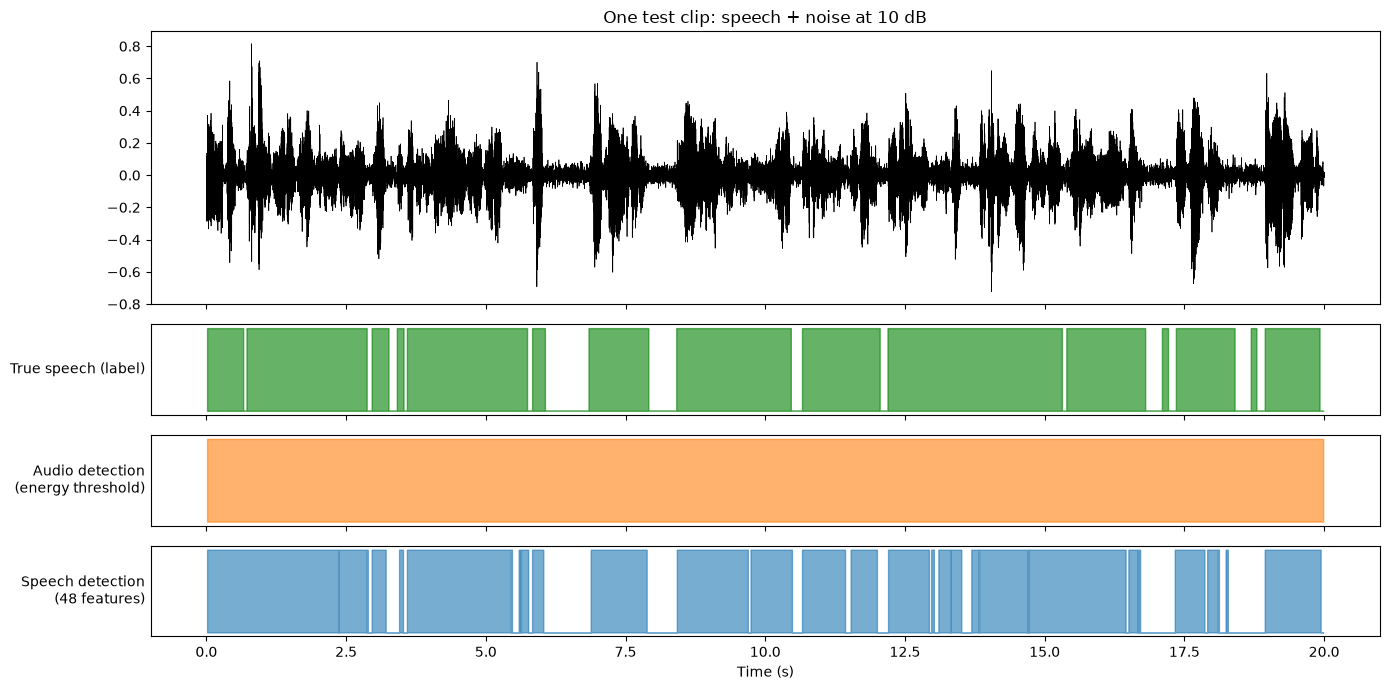

In [11]:
clean = load_wav(list_clips("test", "clean_speech")[0])
noise = load_wav(list_clips("test", "noise_only")[0])
noisy = mix(clean, noise, 10)

feats = extract_features(noisy)
true_speech = speech_labels(clean)
audio_threshold = test_single_feature(train, test, "energy_db", "audio")["threshold"]
audio_decision = feats["energy_db"].values > audio_threshold                  # energy threshold only
speech_decision = linear_model.predict(feats[ALL_FEATURES].values) == 1      # all 48 features
frame_time = (np.arange(len(feats)) * HOP + FRAME / 2) / SR                  # centre of each frame in seconds

fig, axes = plt.subplots(4, 1, figsize=(14, 7), sharex=True, gridspec_kw={"height_ratios": [3, 1, 1, 1]})
axes[0].plot(np.arange(len(noisy)) / SR, noisy, linewidth=0.5, color="black")
axes[0].set_title("One test clip: speech + noise at 10 dB")
for ax, decision, label, colour in [(axes[1], true_speech, "True speech (label)", "green"),
                                    (axes[2], audio_decision, "Audio detection\n(energy threshold)", "tab:orange"),
                                    (axes[3], speech_decision, "Speech detection\n(48 features)", "tab:blue")]:
    ax.fill_between(frame_time, 0, decision.astype(int), step="mid", color=colour, alpha=0.6)
    ax.set_yticks([]); ax.set_ylabel(label, rotation=0, ha="right", va="center", fontsize=10)
axes[-1].set_xlabel("Time (s)")
plt.tight_layout(); plt.show()
display(Audio(np.clip(noisy, -1, 1), rate=SR, normalize=False))

**Result of D2 (one test clip at 10 dB):**
- Audio detection (energy threshold) says "sound" everywhere. This is correct: noise is present in the pauses too.
- Speech detection (48 features) follows the true speech closely: all speech blocks are found and the long pauses are rejected.
- Remaining errors are small: short holes inside speech (weak moments between words), shifted start/end points,
  and very short speech pieces that are missed.


In [13]:
# Which noise clip was mixed into each clean test clip (same rule as build_frame_table)
clean_names = [p.name for p in list_clips("test", "clean_speech")]
noise_names = [p.name for p in list_clips("test", "noise_only")]
noise_of_clip = {name: noise_names[i % len(noise_names)] for i, name in enumerate(clean_names)}

clip_of_frame = zero_db["clip"].values[pause]
per_clip = pd.DataFrame({
    "linear: false alarm": pd.Series(linear_model.predict(zero_db[ALL_FEATURES].values)[pause]).groupby(clip_of_frame).mean(),
    "trees: false alarm": pd.Series(tree_model.predict(zero_db[ALL_FEATURES].values)[pause]).groupby(clip_of_frame).mean(),
})
per_clip.insert(0, "noise mixed in", per_clip.index.map(noise_of_clip))
per_clip = per_clip.sort_values("linear: false alarm", ascending=False)
display(per_clip.round(2))

,noise mixed in,linear: false alarm,trees: false alarm
8.wav,8.wav,1.00,1.00
18.wav,18.wav,0.91,1.00
14.wav,14.wav,0.87,0.67
5.wav,5.wav,0.66,0.79
10.wav,10.wav,0.56,0.60
7.wav,7.wav,0.55,0.30
19.wav,19.wav,0.51,0.15
4.wav,4.wav,0.44,0.28
1.wav,1.wav,0.35,0.19
12.wav,12.wav,0.34,0.25


**Result of E1 (false alarms per test clip, 0 dB):**
- The errors are concentrated in a few noise clips: 8.wav (1.00), 18.wav (0.91), 14.wav (0.87).
  Most other clips are between 0.09 and 0.44.
- Gradient boosting reduces the errors on most clips (e.g. 19.wav 0.51 -> 0.15), but not on the worst ones
  (8.wav stays 1.00, 18.wav 0.91 -> 1.00, 5.wav 0.66 -> 0.79).
- So the problem is in specific noises, not in the model type. Next: what do these noises have in common?

,noise centroid (Hz),bright?,linear: false alarm,trees: false alarm
8.wav,1652.0,True,1.00,1.00
18.wav,1751.0,True,0.91,1.00
14.wav,2918.0,True,0.87,0.67
5.wav,280.0,False,0.66,0.79
10.wav,1055.0,False,0.56,0.60
7.wav,401.0,False,0.55,0.30
19.wav,973.0,False,0.51,0.15
4.wav,408.0,False,0.44,0.28
1.wav,276.0,False,0.35,0.19
12.wav,439.0,False,0.34,0.25


Bright noise clips in train: 3 of 30
Bright noise clips in test : 3 of 20 -> ['8.wav', '18.wav', '14.wav']


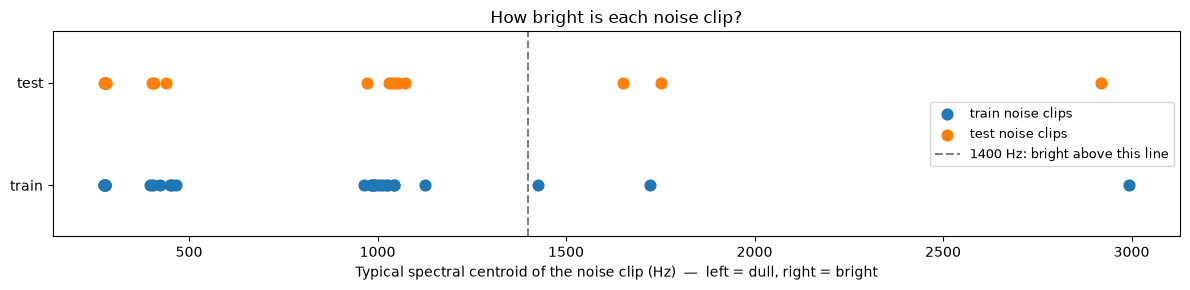

In [14]:
def noise_brightness(table):
    """Typical spectral centroid (Hz) of every noise-only clip, sorted from dull to bright."""
    noise_part = table[table["condition"] == "noise only"]
    return noise_part.groupby("clip")["centroid"].median().sort_values()

BRIGHT_HZ = 1400                                   # we call a noise clip "bright" above this centroid
train_centroid = noise_brightness(train)
test_centroid = noise_brightness(test)
bright_test_clips = test_centroid[test_centroid > BRIGHT_HZ].index.tolist()
bright_train_clips = train_centroid[train_centroid > BRIGHT_HZ].index.tolist()

# Table: brightness of each test noise next to its 0 dB false alarm (from E1)
brightness_vs_errors = per_clip[["linear: false alarm", "trees: false alarm"]].copy()
brightness_vs_errors.insert(0, "noise centroid (Hz)", test_centroid.reindex(brightness_vs_errors.index).round(0))
brightness_vs_errors.insert(1, "bright?", brightness_vs_errors["noise centroid (Hz)"] > BRIGHT_HZ)
display(brightness_vs_errors.round(2))

print(f"Bright noise clips in train: {len(bright_train_clips)} of {len(train_centroid)}")
print(f"Bright noise clips in test : {len(bright_test_clips)} of {len(test_centroid)} -> {bright_test_clips}")

# Plot: every noise clip as a dot on the centroid axis
fig, ax = plt.subplots(figsize=(12, 3))
ax.scatter(train_centroid.values, np.zeros(len(train_centroid)), s=60, label="train noise clips")
ax.scatter(test_centroid.values, np.ones(len(test_centroid)), s=60, label="test noise clips")
ax.axvline(BRIGHT_HZ, color="grey", linestyle="--", label=f"{BRIGHT_HZ} Hz: bright above this line")
ax.set_yticks([0, 1]); ax.set_yticklabels(["train", "test"]); ax.set_ylim(-0.5, 1.5)
ax.set_xlabel("Typical spectral centroid of the noise clip (Hz)  —  left = dull, right = bright")
ax.set_title("How bright is each noise clip?")
ax.legend(loc="center right", fontsize=9)
plt.tight_layout(); plt.show()

In [15]:
noise_test = test[test["condition"] == "noise only"]
dull_test_clips = test_centroid[test_centroid < 300].index.tolist()
columns = ["energy_db", "harmonicity", "amdf_periodicity", "centroid", "zcr", "energy_db_std", "harmonicity_std"]
compare = pd.DataFrame({
    f"bright noise ({len(bright_test_clips)} clips)": noise_test[noise_test["clip"].isin(bright_test_clips)][columns].median(),
    f"dull noise ({len(dull_test_clips)} clips)": noise_test[noise_test["clip"].isin(dull_test_clips)][columns].median(),
    "speech (clean)": test[(test["klass"] == "speech") & (test["condition"] == "clean speech")][columns].median(),
})
display(compare.round(3))

,bright noise (3 clips),dull noise (8 clips),speech (clean)
energy_db,-35.444,-32.668,-22.464
harmonicity,0.205,0.236,0.512
amdf_periodicity,0.184,0.240,0.583
centroid,1820.279,277.704,1097.034
zcr,0.158,0.025,0.060
energy_db_std,1.012,1.594,6.472
harmonicity_std,0.059,0.107,0.151


Eksen üzerinde sıralama şöyle: boğuk gürültü → konuşma → tiz gürültü. Train’deki gürültülerin %90'ı boğuk. Model bu yüzden şunu öğrenmiş: “centroid düşükse gürültü, yükseldikçe konuşma.” Tiz gürültü gelince centroid’i konuşmanınkinden de yüksek. Model bunu “çok konuşma” diye yorumluyor. Hiç görmediği bir bölgeye öğrendiği kuralı uzatıyor.

In [16]:
bright = zero_db["clip"].isin(bright_test_clips).values      # 0 dB test frames that contain bright noise


def zero_db_errors(model, features):
    """On the 0 dB test mixtures: false alarms in pauses (bright / other noise) and share of speech found."""
    predicted = model.predict(zero_db[features].values)
    return {
        "false alarm, bright noise": predicted[pause & bright].mean(),
        "false alarm, other noise": predicted[pause & ~bright].mean(),
        "speech found": predicted[~pause].mean(),
    }

# The same question on the train mixtures (noise the model has seen)
train_zero = train[train["condition"] == "speech + noise 0 dB"]
train_pause = (train_zero["speech"] == 0).values
train_bright = train_zero["clip"].isin(bright_train_clips).values

rows = []
for name, model in models.items():
    seen = model.predict(train_zero[ALL_FEATURES].values)
    new = zero_db_errors(model, ALL_FEATURES)
    rows.append({
        "model": name,
        "bright noise: seen in training": seen[train_pause & train_bright].mean(),
        "bright noise: new (test)": new["false alarm, bright noise"],
        "other noise: seen in training": seen[train_pause & ~train_bright].mean(),
        "other noise: new (test)": new["false alarm, other noise"],
    })
table_e4 = pd.DataFrame(rows).set_index("model")
display(table_e4.round(3))
table_e4.round(4).to_csv(results_dir / "table_E4_seen_vs_new.csv")

,bright noise: seen in training,bright noise: new (test),other noise: seen in training,other noise: new (test)
model,,,,
logistic regression,0.505,0.934,0.299,0.317
gradient boosting,0.109,0.899,0.112,0.233




Sayılar 0 dB’deki aralarda “konuşma” denen frame oranı; düşük olması iyi.

1. Gradient boosting gördüğü tiz gürültüyü öğrenmiş, ama genelleyememiş.

Eğitimde gördüğü tiz gürültüde: 0.109 (çok iyi).
Hiç görmediği tiz gürültüde: 0.899 (çok kötü).

Model train’deki 3 tiz gürültüyü adeta ezberlemiş: “bu belirli sesler gürültü”. Ama “tiz ve periyodik olmayan ses gürültüdür” genel kuralını çıkaramamış. 3 örnekten genel bir kural çıkarmak zaten zor.

2. Logistic regression gördüğü tiz gürültüyü bile öğrenememiş.

Gördüğü tiz gürültüde: 0.505. Yeni tiz gürültüde: 0.934.

Bu model düz bir çizgiyle ayırıyor; “centroid yükseldikçe konuşma” ile “centroid çok yüksekse tekrar gürültü” kuralını aynı anda kuramıyor. Train’deki tiz örnekler de çok az olduğu için bunları önemsememiş.

3. Diğer gürültülerde (çoğunluk) seen ve new farkı küçük.

Linear: 0.299 → 0.317. Trees: 0.112 → 0.233.

Model bol örnek gördüğü gürültü türlerinde yeni kliplere de iyi genelleyebiliyor.

Extra noise clips: 60
Extra clips that are copies of existing clips: none
Bright extra clips: 15 of 60


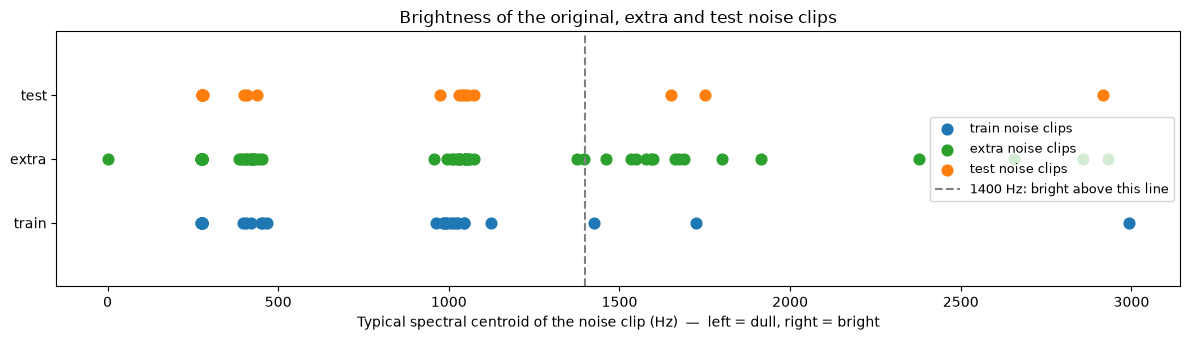

In [17]:
extra_files = sorted((DATA_DIR / "train" / "noise_extra").glob("*.wav"))
extra_noises = {path.name: load_wav(path) for path in extra_files}
print("Extra noise clips:", len(extra_noises))

# Copy check: is an extra clip identical to a clip we already have? (compare the first 2 seconds)
known = {f"train/{p.name}": load_wav(p)[:2 * SR] for p in list_clips("train", "noise_only")}
known.update({f"test/{p.name}": load_wav(p)[:2 * SR] for p in list_clips("test", "noise_only")})
copies = [(name, other) for name, y in extra_noises.items() for other, start in known.items()
          if len(start) == 2 * SR and len(y) >= 2 * SR and np.allclose(y[:2 * SR], start, atol=1e-3)]
print("Extra clips that are copies of existing clips:", copies if copies else "none")

# Brightness of the extra clips
extra_centroid = pd.Series({name: np.median(extract_features(y)["centroid"])
                            for name, y in extra_noises.items()}).sort_values()
bright_extra = extra_centroid[extra_centroid > BRIGHT_HZ].index.tolist()
print(f"Bright extra clips: {len(bright_extra)} of {len(extra_centroid)}")

fig, ax = plt.subplots(figsize=(12, 3.5))
ax.scatter(train_centroid.values, np.zeros(len(train_centroid)), s=60, label="train noise clips")
ax.scatter(extra_centroid.values, np.full(len(extra_centroid), 0.5), s=60, color="tab:green", label="extra noise clips")
ax.scatter(test_centroid.values, np.ones(len(test_centroid)), s=60, label="test noise clips")
ax.axvline(BRIGHT_HZ, color="grey", linestyle="--", label=f"{BRIGHT_HZ} Hz: bright above this line")
ax.set_yticks([0, 0.5, 1]); ax.set_yticklabels(["train", "extra", "test"]); ax.set_ylim(-0.5, 1.5)
ax.set_xlabel("Typical spectral centroid of the noise clip (Hz)  —  left = dull, right = bright")
ax.set_title("Brightness of the original, extra and test noise clips")
ax.legend(loc="center right", fontsize=9)
plt.tight_layout(); plt.show()

60 ek gürültü klibi var, ve hiçbiri mevcut train veya test kliplerinin birebir kopyası değil. Bu önemli: test kliplerinin kopyası eğitime girseydi sonuç hileli olurdu.
15 tanesi tiz (yeşil noktalar, 1400 Hz’in sağında). Orijinal train setinde sadece 3 tiz gürültü vardı. Model artık 3 yerine 18 tiz gürültü görecek, ve bu klipler 1400–3000 Hz arasına yayılmış.
Lejant, sağdaki birkaç yeşil noktayı (~2650–2950 Hz) kapatıyor. Soluk görünen noktalar onlar; yine de sayıma dahiller.
En solda centroid’i 0 Hz olan tek bir klip var. Bu bir aykırı değer, ama 60 klipten biri olduğu için sonucu belirgin şekilde etkilemez.
Kopya kontrolü sadece birebir aynı dosyaları yakalıyor. Grafikte ek klipler de aynı centroid kümelerine düşüyor (~275, ~400, ~1000 Hz). Yani aynı kaynaktan farklı kayıtlar olabilir. Bu, E2'de belirttiğimiz kısıtla aynı.

In [18]:
def frames_for_extra_noise(noises):
    """Same recipe as build_frame_table: the noise alone, and the noise mixed into a clean train clip at every SNR."""
    clean_files = list_clips("train", "clean_speech")
    tables = []
    for k, (name, noise) in enumerate(noises.items()):
        table = extract_features(noise)
        table["klass"], table["condition"], table["clip"] = "noise", "noise only", "extra_" + name
        tables.append(table)

        clean = load_wav(clean_files[k % len(clean_files)])      # reuse the train speech clips in turn
        is_speech = speech_labels(clean)
        for snr_db in SNR_LEVELS:
            table = extract_features(mix(clean, noise, snr_db))
            table["klass"] = np.where(is_speech, "speech", "noise")
            table["condition"], table["clip"] = f"speech + noise {snr_db} dB", "extra_" + name
            tables.append(table)
    extra = pd.concat(tables, ignore_index=True)
    extra["audio"] = (extra["klass"] != "silence").astype(int)
    extra["speech"] = (extra["klass"] == "speech").astype(int)
    return extra

extra_all = frames_for_extra_noise(extra_noises)
extra_dull = extra_all[~extra_all["clip"].isin(["extra_" + name for name in bright_extra])]   # control: no bright clips
print("Rows: train", len(train), "| extra (all)", len(extra_all), "| extra (dull only)", len(extra_dull))

Rows: train 299700 | extra (all) 479520 | extra (dull only) 359640


In [19]:
training_sets = {
    "1. original train": train,
    "2. + all extra noise": pd.concat([train, extra_all], ignore_index=True),
    "3. + extra noise without the bright ones": pd.concat([train, extra_dull], ignore_index=True),
}

rows = []
for set_name, table in training_sets.items():
    for model_name in ["logistic regression", "gradient boosting"]:
        if model_name == "logistic regression":
            model = fit_model(table, ALL_FEATURES, "speech")
        else:
            model = fit_trees(table, ALL_FEATURES)
        row = {"model": model_name, "training data": set_name, **zero_db_errors(model, ALL_FEATURES)}
        row["speech detection, whole test set"] = scores(test["speech"].values,
                                                         model.predict(test[ALL_FEATURES].values))["balanced_acc"]
        rows.append(row)
table_f3 = pd.DataFrame(rows).set_index(["model", "training data"])
display(table_f3.round(3))
table_f3.round(4).to_csv(results_dir / "table_F3_more_noise.csv")

,,"false alarm, bright noise","false alarm, other noise",speech found,"speech detection, whole test set"
model,training data,,,,
logistic regression,1. original train,0.934,0.317,0.934,0.926
gradient boosting,1. original train,0.899,0.233,0.940,0.933
logistic regression,2. + all extra noise,0.760,0.313,0.920,0.926
gradient boosting,2. + all extra noise,0.395,0.235,0.922,0.940
logistic regression,3. + extra noise without the bright ones,0.937,0.332,0.939,0.926
gradient boosting,3. + extra noise without the bright ones,0.915,0.230,0.935,0.937


1. Tiz gürültü eklemek hatayı ciddi şekilde düşürdü. Ağaç modelinde %90'dan %40'a indi; neredeyse yarıdan fazla azaldı. Linear modelde de düştü (0.934 → 0.760), ama daha az.

2. Kontrol grubu iyileşmenin sebebini gösteriyor. Sadece boğuk ek gürültü eklenince hiçbir şey değişmedi (0.899 → 0.915, aynı seviye). Yani iyileşmeyi sağlayan şey “daha çok veri” değil, özellikle tiz gürültü. E3 ve E4'teki açıklama doğrulandı: model tiz gürültüyü yeterince görmediği için yanlış öğrenmişti.

3. Ağaç modeli ek veriden çok daha iyi faydalandı. E4'te gördüğümüz gibi linear model “orta centroid = konuşma, çok yüksek centroid = gürültü” kuralını tek bir düz çizgiyle kuramıyor. Ağaç modeli kurabiliyor.